This code is for predicting words to complete an incomplete sentence using Decoder Transformer

In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import copy

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

In [ ]:
class GPT2CausalAttention(nn.Module):
    """ GPT-2 Unidirectional Causal Multi-Head Attention Layer """
    def __init__(self, d_model=768, n_head=12):
        super().__init__()
        self.d_model = d_model
        self.n_head = n_head
        self.head_dim = d_model // n_head

        # GPT-2 packs Q, K, V projections into a single massive Linear Layer (768 -> 768 * 3)
        self.c_attn = nn.Linear(d_model, 3 * d_model)
        # Final output projection head matrix W^(o)
        self.c_proj = nn.Linear(d_model, d_model)

    def forward(self, x):
        B, T, C = x.size() # Batch size, Sequence length, Dimension channel (768)

        # Calculate Query, Key, Value vectors for all heads simultaneously
        q, k, v = self.c_attn(x).split(self.d_model, dim=2)

        # Rearrange shapes to parallel process across heads: (B, n_head, T, head_dim)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        # Matrix Dot-Product Attention: Q x K^T scaled
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)

        # ─── THE DECODER CAUSAL MASK ───
        # Create an upper triangular block to force future tokens to negative infinity
        mask = torch.triu(torch.ones(T, T, device=x.device), diagonal=1).bool()
        scores = scores.masked_fill(mask.unsqueeze(0).unsqueeze(1), float('-inf'))

        # Normalize weights via softmax and multiply by Value matrix (V)
        weights = F.softmax(scores, dim=-1)
        y = torch.matmul(weights, v)

        # Re-assemble all 12 heads back into a unified horizontal matrix shape (B, T, C)
        y = y.transpose(1, 2).contiguous().view(B, T, C)

        return self.c_proj(y)

class GPT2MLP(nn.Module):
    """ GPT-2 Position-Wise Feed-Forward Network """
    def __init__(self, d_model=768):
        super().__init__()
        # Expand dimension by 4x internally (768 -> 3072)
        self.c_fc   = nn.Linear(d_model, 4 * d_model)
        self.c_proj = nn.Linear(4 * d_model, d_model)

    def forward(self, x):
        # GPT-2 strictly relies on the GELU non-linear activation function
        x = F.gelu(self.c_fc(x))
        return self.c_proj(x)

class GPT2DecoderBlock(nn.Module):
    """ A Single Complete GPT-2 Decoder Layer Layer """
    def __init__(self, d_model=768, n_head=12):
        super().__init__()
        # In GPT-2, Layer Normalization occurs BEFORE the attention/MLP layers (Pre-LN)
        self.ln_1 = nn.LayerNorm(d_model)
        self.attn = GPT2CausalAttention(d_model, n_head)
        self.ln_2 = nn.LayerNorm(d_model)
        self.mlp  = GPT2MLP(d_model)

    def forward(self, x):
        # Residual Skip Connections + Causal Self-Attention block
        x = x + self.attn(self.ln_1(x))
        # Residual Skip Connections + Multi-Layer Perceptron block
        x = x + self.mlp(self.ln_2(x))
        return x


In [ ]:
#Complete Scratch Language Model (Wrapper for Embeddings & LM Head)

class ScratchGPT2LanguageModel(nn.Module):
    def __init__(self, vocab_size=50257, d_model=768, n_head=12):
        super().__init__()
        # Token Embeddings matrix W_e
        self.wte = nn.Embedding(vocab_size, d_model)
        # GPT-2 also requires a Positional Embedding Matrix (wpe)
        self.wpe = nn.Embedding(1024, d_model)
        # Custom Causal Decoder Layer block
        self.decoder_block = GPT2DecoderBlock(d_model, n_head)
        # Final Layer Norm stage (which stabilizes the numbers by calculating their mean and variance, standardizing the scale)
        self.ln_f = nn.LayerNorm(d_model)
        # Language Model Head: maps 768 vector back to prediction scores across vocabulary
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)

    def forward(self, input_ids):
        B, T = input_ids.size()
        pos = torch.arange(0, T, dtype=torch.long, device=input_ids.device)

        # Combine Token Embeddings and Positional Embeddings
        x = self.wte(input_ids) + self.wpe(pos)

        x = self.decoder_block(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)
        return logits

In [ ]:
if __name__ == "__main__":
    print("Loading pre-trained weights from OpenAI GPT-2...")
    hf_tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
    hf_model = AutoModelForCausalLM.from_pretrained("openai-community/gpt2")

    # Initialize our scratch-built architecture skeleton
    custom_model = ScratchGPT2LanguageModel()
    random_weight_snapshot = custom_model.decoder_block.attn.c_attn.weight.detach().clone().cpu().numpy()

    # Copy OpenAI's real learned weights directly into our custom variables
    with torch.no_grad():
        custom_model.wte.weight.copy_(hf_model.transformer.wte.weight)
        custom_model.wpe.weight.copy_(hf_model.transformer.wpe.weight)

        # Pull out the first layer of GPT-2 and match it to our decoder block parameters
        hf_layer = hf_model.transformer.h[0]
        custom_model.decoder_block.ln_1.weight.copy_(hf_layer.ln_1.weight)
        custom_model.decoder_block.ln_1.bias.copy_(hf_layer.ln_1.bias)

        # Conv1D layers inside HuggingFace have transposed formats, transposing back to match standard nn.Linear
        custom_model.decoder_block.attn.c_attn.weight.copy_(hf_layer.attn.c_attn.weight.t())
        custom_model.decoder_block.attn.c_attn.bias.copy_(hf_layer.attn.c_attn.bias)
        custom_model.decoder_block.attn.c_proj.weight.copy_(hf_layer.attn.c_proj.weight.t())
        custom_model.decoder_block.attn.c_proj.bias.copy_(hf_layer.attn.c_proj.bias)

        custom_model.decoder_block.ln_2.weight.copy_(hf_layer.ln_2.weight)
        custom_model.decoder_block.ln_2.bias.copy_(hf_layer.ln_2.bias)

        custom_model.decoder_block.mlp.c_fc.weight.copy_(hf_layer.mlp.c_fc.weight.t())
        custom_model.decoder_block.mlp.c_fc.bias.copy_(hf_layer.mlp.c_fc.bias)
        custom_model.decoder_block.mlp.c_proj.weight.copy_(hf_layer.mlp.c_proj.weight.t())
        custom_model.decoder_block.mlp.c_proj.bias.copy_(hf_layer.mlp.c_proj.bias)

        custom_model.ln_f.weight.copy_(hf_model.transformer.ln_f.weight)
        custom_model.ln_f.bias.copy_(hf_model.transformer.ln_f.bias)
        custom_model.lm_head.weight.copy_(hf_model.lm_head.weight)

    print("Weights loaded successfully! Running auto-regressive verification loop...\n")

    # Starting Input Prompt
    prompt = "attention is all you"
    input_ids = hf_tokenizer(prompt, return_tensors="pt").input_ids

    # Generate 2 tokens auto-regressively
    for step in range(10):
        current_visible_sequence = hf_tokenizer.decode(input_ids[0])
        print(f"Step {step + 1} Input: '{current_visible_sequence}'")

        with torch.no_grad():
            # Run inference through our custom structure
            logits = custom_model(input_ids)

            # Isolate the final logit index
            next_token_logits = logits[0, -1, :]

            # Predict the next index
            predicted_token_id = torch.argmax(next_token_logits, dim=-1).unsqueeze(0).unsqueeze(0)
            predicted_word = hf_tokenizer.decode(predicted_token_id[0])
            print(f"👉 Custom Scratch Decoder Predicted: '{predicted_word}'\n")

            # Append token back to sequence loop
            input_ids = torch.cat([input_ids, predicted_token_id], dim=-1)

    print("-" * 65)
    print(f"Final Sentence Result: '{hf_tokenizer.decode(input_ids[0])}'")


Loading pre-trained weights from OpenAI GPT-2...


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Weights loaded successfully! Running auto-regressive verification loop...

Step 1 Input: 'attention is all you'
👉 Custom Scratch Decoder Predicted: ''re'

Step 2 Input: 'attention is all you're'
👉 Custom Scratch Decoder Predicted: ' going'

Step 3 Input: 'attention is all you're going'
👉 Custom Scratch Decoder Predicted: ' to'

Step 4 Input: 'attention is all you're going to'
👉 Custom Scratch Decoder Predicted: ' get'

Step 5 Input: 'attention is all you're going to get'
👉 Custom Scratch Decoder Predicted: ' rid'

Step 6 Input: 'attention is all you're going to get rid'
👉 Custom Scratch Decoder Predicted: ' rid'

Step 7 Input: 'attention is all you're going to get rid rid'
👉 Custom Scratch Decoder Predicted: ' rid'

Step 8 Input: 'attention is all you're going to get rid rid rid'
👉 Custom Scratch Decoder Predicted: ' rid'

Step 9 Input: 'attention is all you're going to get rid rid rid rid'
👉 Custom Scratch Decoder Predicted: ' rid'

Step 10 Input: 'attention is all you're going to get

In [ ]:
print(input_ids)

tensor([[1078, 1463,  318,  477,  345,  821, 1016,  284,  651]])


PLOT: Initial (Random) vs True Weights Comparison

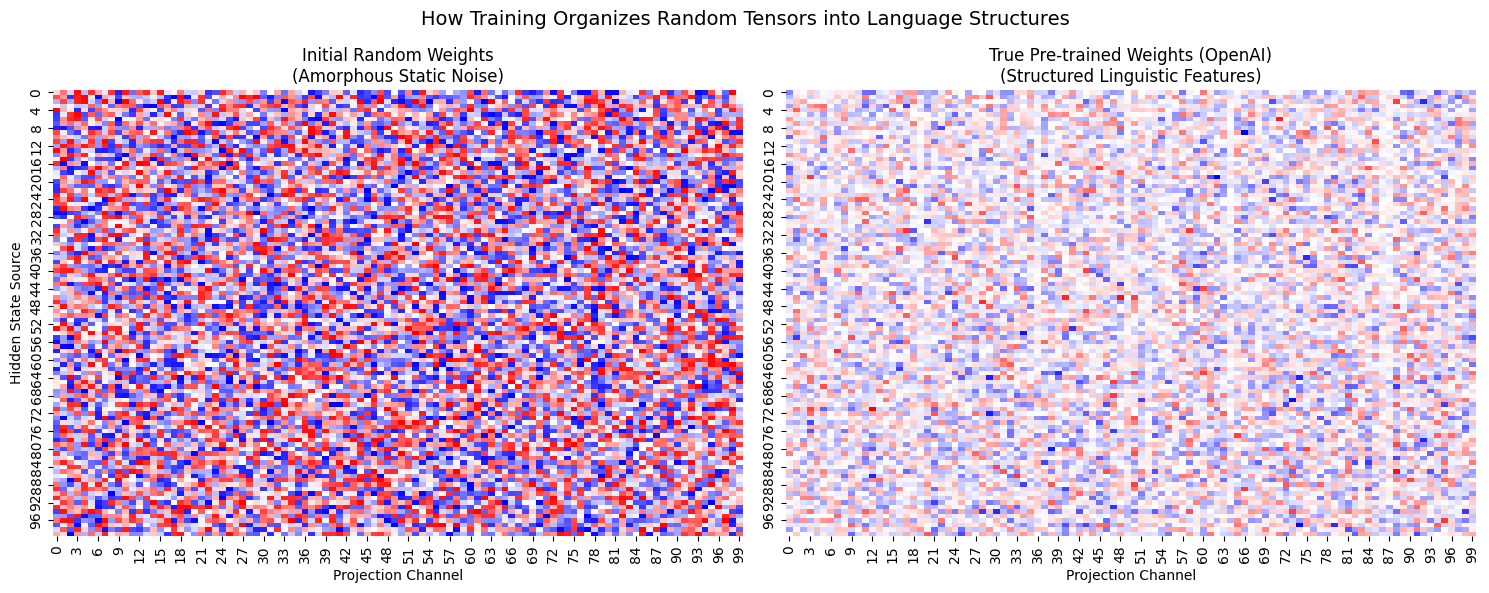

In [ ]:

#Extract weights after copying OpenAI parameters (Run this at the very end of your script)
trained_weight_snapshot = custom_model.decoder_block.attn.c_attn.weight.detach().numpy()
positional_matrix = custom_model.wpe.weight.detach().numpy()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Slice out a 100x100 window of the massive projection matrix for crisp viewing
sns.heatmap(random_weight_snapshot[:100, :100], cmap="bwr", ax=axes[0], cbar=False)
axes[0].set_title("Initial Random Weights\n(Amorphous Static Noise)")
axes[0].set_xlabel("Projection Channel")
axes[0].set_ylabel("Hidden State Source")

sns.heatmap(trained_weight_snapshot[:100, :100], cmap="bwr", ax=axes[1], cbar=False)
axes[1].set_title("True Pre-trained Weights (OpenAI)\n(Structured Linguistic Features)")
axes[1].set_xlabel("Projection Channel")

plt.suptitle("How Training Organizes Random Tensors into Language Structures", fontsize=14)
plt.tight_layout()
plt.show()


In [ ]:
# PLOT 2: Visualizing the Positional Embedding Matrix

plt.figure(figsize=(12, 5))
# Plot the first 50 token positions across their first 150 feature channels
sns.heatmap(positional_matrix[:50, :150], cmap="Spectral", center=0)
plt.title("GPT-2 Learned Positional Embedding Space (First 50 Positions x 150 Channels)")
plt.xlabel("Hidden Coordinate Vector Dimensions")
plt.ylabel("Token Chronological Position Index")
plt.tight_layout()
plt.show()